In [1]:
import hydra
from omegaconf import DictConfig
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from numpy.typing import NDArray

In [2]:
from eo_toolkit import (
    load_cached_sentinel1_as_numpy_tensor,
    compute_harmonic_baselines,
    slice_tensor_with_time_interval,
    compute_sentinel1_radar_index,
    compute_expected_baseline_and_residuals,
)

In [3]:
def plot_random_pixel_baselines(
    data_tensor: NDArray[np.float32],
    coefficients: NDArray[np.float64],
    t_baseline: NDArray[np.float64],
    dates: NDArray[np.datetime64],
    band_idx: int = 1,  # e.g., 1 for VH band
    n_samples: int = 9
) -> None:
    """Plots a grid of randomly selected pixels comparing raw baseline time series
    against the fitted harmonic model.
    """
    _, n_bands, height, width = data_tensor.shape

    # Randomly select 9 distinct pixel coordinates (h, w)
    np.random.seed(42)
    rand_h = np.random.randint(0, height, size=n_samples)
    rand_w = np.random.randint(0, width, size=n_samples)

    # Reconstruct design matrix for the baseline period to compute fitted curves
    n_coeffs = coefficients.shape[-1]
    num_harmonics = (n_coeffs - 1) // 2

    X_cols = [np.ones_like(t_baseline)]
    for k in range(1, num_harmonics + 1):
        X_cols.append(np.cos(2.0 * np.pi * k * t_baseline))
        X_cols.append(np.sin(2.0 * np.pi * k * t_baseline))
    X = np.column_stack(X_cols)

    fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
    axes = axes.flatten()

    for idx, (h, w) in enumerate(zip(rand_h, rand_w)):
        ax = axes[idx]

        # Extract raw time series and fitted coefficients for this pixel/band
        y_raw = data_tensor[:, band_idx, h, w]
        beta = coefficients[band_idx, h, w, :]

        # Compute harmonic fit
        y_fit = X @ beta

        # Plot
        ax.plot(dates, y_raw, 'ko', markersize=3, alpha=0.5, label='Raw Data')
        ax.plot(dates, y_fit, 'r-', linewidth=2, label='Harmonic Fit')

        ax.set_title(f"Pixel [{h}, {w}]", fontsize=10)
        ax.grid(True, linestyle='--', alpha=0.5)
        if idx == 0:
            ax.legend(loc='upper right', fontsize=8)

    plt.suptitle(f"Baseline Harmonic Fits (Band {band_idx}) - Random 3x3 Sample", fontsize=14)
    plt.tight_layout()
    plt.show()

In [4]:
darney = "sentinel1_lat_48.008_lon_6.0816_size_3000"
path_to_data = Path("../data") / darney

sentinel1_data = load_cached_sentinel1_as_numpy_tensor(path_to_data)

baseline_start_date = "2016-01-01"
baseline_end_date = "2017-12-31"  # Scolyte infestation started in 2018

observation_start_date = "2018-01-01"
observation_end_date = "2021-12-31"

nb_harmonics = 2

In [5]:
# Compute the radar index, and concatenate to the data tensor as an additional band
radar_index_tensor = compute_sentinel1_radar_index(sentinel1_data["bands"], vv_index=0, vh_index=1)
data_tensor = np.concatenate([sentinel1_data["bands"], radar_index_tensor], axis=1)

In [6]:
baseline_data_tensor, baseline_coefficients, baseline_dates, baseline_t = compute_harmonic_baselines(
    data_tensor=data_tensor,
    dates=sentinel1_data["dates"],
    start_date=baseline_start_date,
    end_date=baseline_end_date,
    nb_harmonics=nb_harmonics
)

# Shape is (bands, height, width, 5) for 2 harmonics (intercept + 2*cos + 2*sin)
print(f"Baseline coefficients shape: {baseline_coefficients.shape}")

Baseline coefficients shape: (3, 104, 105, 5)


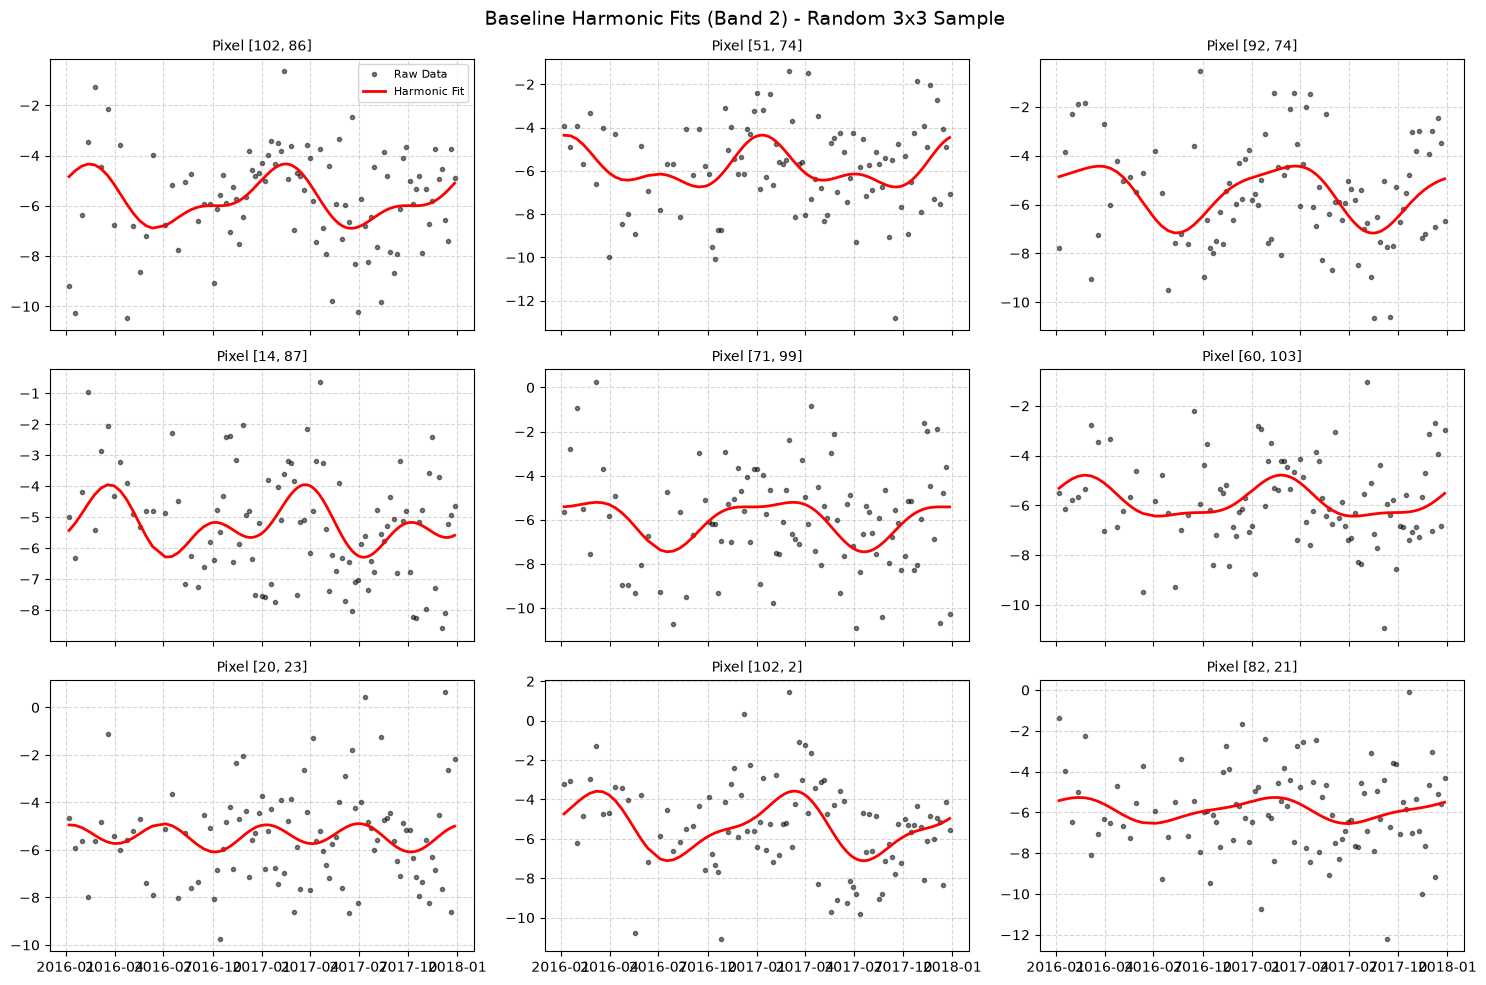

In [7]:
# Visualize 3x3 random pixel fits
plot_random_pixel_baselines(
    data_tensor=baseline_data_tensor,
    coefficients=baseline_coefficients,
    t_baseline=baseline_t,
    dates=baseline_dates,
    band_idx=2,  # VH band
    n_samples=9
)

In [8]:
baseline_expected, residuals, monitoring_data_tensor, monitoring_dates = compute_expected_baseline_and_residuals(
    data_tensor=data_tensor,
    dates=sentinel1_data["dates"],
    coefficients=baseline_coefficients,
    start_date=observation_start_date,
    end_date=observation_end_date,
    nb_harmonics=nb_harmonics,
)

In [9]:
def plot_monitoring_and_residuals(
    monitoring_data: NDArray[np.float32],
    baseline_expected: NDArray[np.float32],
    residuals: NDArray[np.float32],
    dates: NDArray[np.datetime64],
    band_idx: int = 2,  # Default to band 2 (VH and VV)
    band_name: str = "VH - VV Radar Index",
    n_samples: int = 4,
    seed: int = 0
) -> None:
    """Plots a grid of randomly selected pixels comparing the monitoring observations 
    against the expected baseline, alongside their resulting residuals.

    Parameters:
    - monitoring_data: Sliced 4D tensor of observed values during the monitoring period.
    - baseline_expected: Expected baseline 4D tensor predicted by the harmonic model.
    - residuals: Computed 4D deviation tensor (baseline - observed).
    - dates: Array of datetimes corresponding to the monitoring period.
    - band_idx: Index of the band/feature to visualize.
    - band_name: Label description of the band for plot titles.
    - n_samples: Number of random spatial pixels to sample and plot.
    - seed: Random seed for reproducible pixel selection.
    """
    n_time, n_bands, height, width = monitoring_data.shape
    
    np.random.seed(seed)
    rand_h = np.random.randint(0, height, size=n_samples)
    rand_w = np.random.randint(0, width, size=n_samples)
    
    fig, axes = plt.subplots(n_samples, 2, figsize=(14, 3 * n_samples), sharex=True)
    if n_samples == 1:
        axes = np.expand_dims(axes, axis=0)
        
    for idx, (h, w) in enumerate(zip(rand_h, rand_w)):
        # Extract time series for the selected pixel
        obs = monitoring_data[:, band_idx, h, w]
        pred = baseline_expected[:, band_idx, h, w]
        res = residuals[:, band_idx, h, w]
        
        # --- Left Column: Observations vs Expected Baseline ---
        ax_ts = axes[idx, 0]
        ax_ts.plot(dates, obs, 'ko-', markersize=3, alpha=0.5, label='Observed Data')
        ax_ts.plot(dates, pred, 'r-', linewidth=2, label='Expected Baseline')
        ax_ts.set_ylabel("Backscatter / Index", fontsize=9)
        ax_ts.set_title(f"Pixel [{h}, {w}] - {band_name}", fontsize=10)
        ax_ts.grid(True, linestyle='--', alpha=0.5)
        if idx == 0:
            ax_ts.legend(loc='upper right', fontsize=8)
            
        # --- Right Column: Residuals (Deviation Magnitude) ---
        ax_res = axes[idx, 1]
        ax_res.plot(dates, res, 'b-', linewidth=1.5, label='Residual (Base - Obs)')
        ax_res.axhline(0, color='gray', linestyle='--', linewidth=1)
        ax_res.fill_between(dates, res, 0, where=(res > 0), color='salmon', alpha=0.3, label='Positive Deviation (Stress)')
        ax_res.set_ylabel("Residual Value", fontsize=9)
        ax_res.set_title(f"Pixel [{h}, {w}] - Residual Deviation", fontsize=10)
        ax_res.grid(True, linestyle='--', alpha=0.5)
        if idx == 0:
            ax_res.legend(loc='upper right', fontsize=8)

    plt.xlabel("Monitoring Date", fontsize=10)
    plt.tight_layout()
    plt.show()

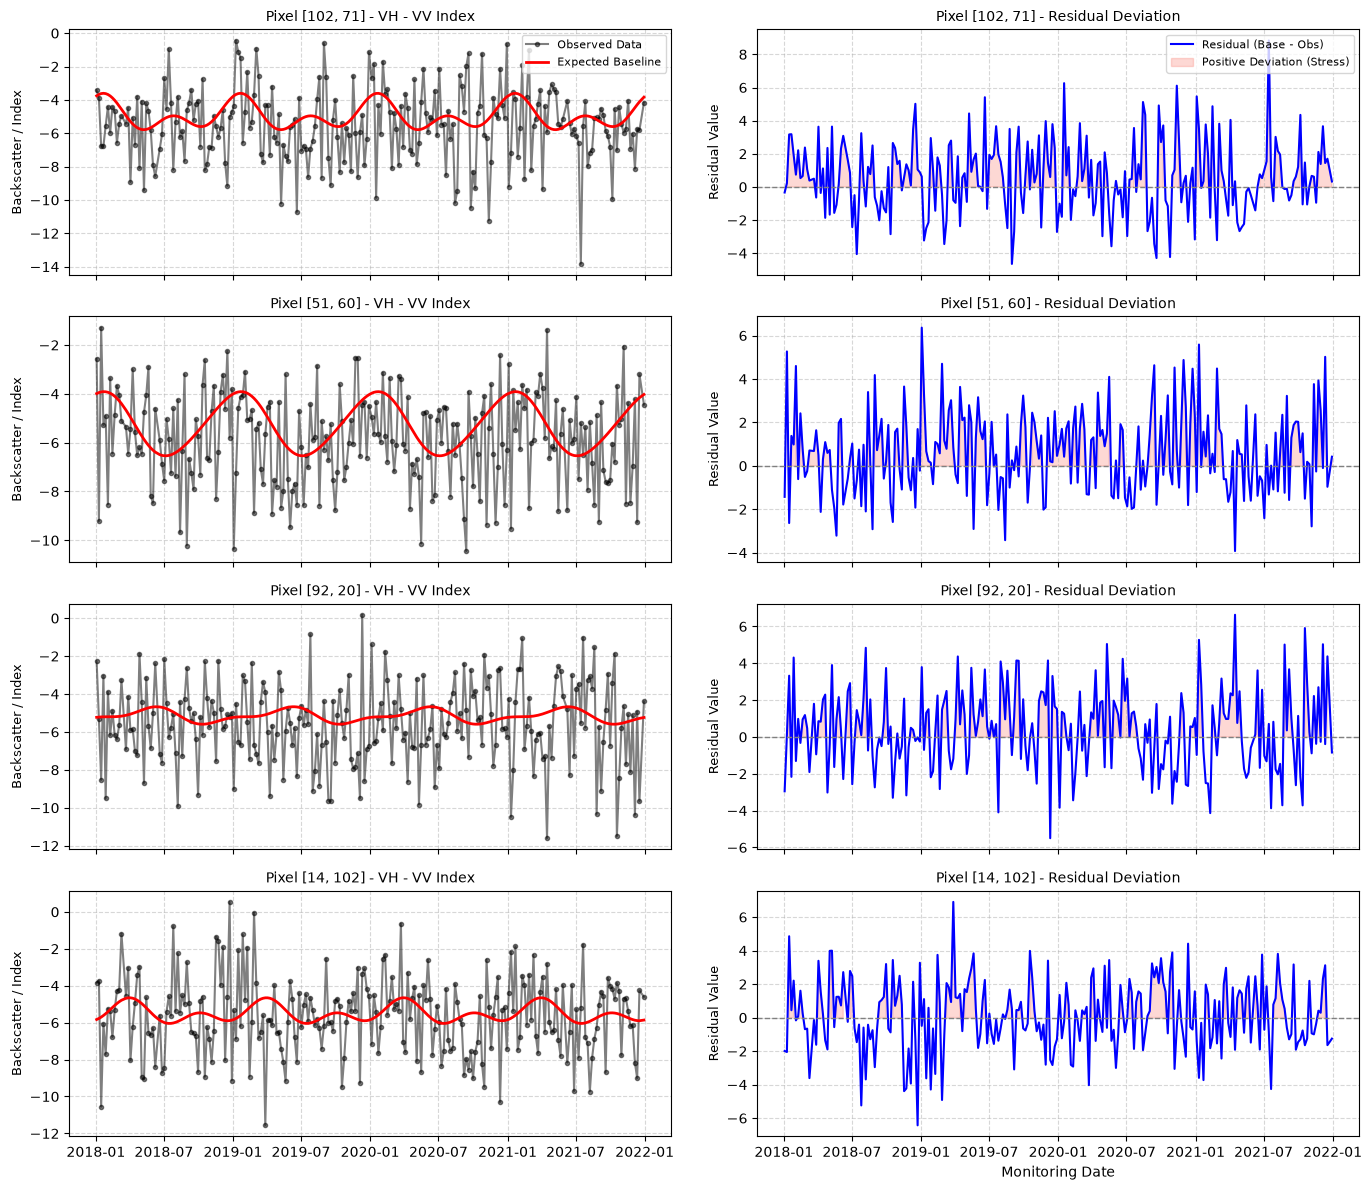

In [10]:
plot_monitoring_and_residuals(
    monitoring_data=monitoring_data_tensor,
    baseline_expected=baseline_expected,
    residuals=residuals,
    dates=monitoring_dates,
    band_idx=2,  # Index band (VV, VH, and index is at position 2)
    band_name="VH - VV Index",
    n_samples=4
)